# Recomendação de cultivo inteligente — Entrega 1

Notebook da Entrega 1 (2026-11-08). Cobre os itens do enunciado: problema e objetivo, exploração dos dados (hipóteses, EDA e variáveis relevantes), metodologia, primeiro experimento (EXP-001) e próximos passos, com dificuldades e melhorias. O notebook **não treina modelos**: ele lê os relatórios já gerados pelo código do projeto (`reports/`) e os apresenta com interpretação.

## Problema, objetivo e delimitação

O objetivo é construir um modelo que, a partir de sete medições de solo e clima (`N`, `P`, `K`, `temperature`, `humidity`, `ph`, `rainfall`), **indique qual das 22 culturas do dataset corresponde àquelas condições**: uma classificação multiclasse. *Exemplo:* entrada com N, P, K, pH, temperatura, umidade e chuva medidos → saída `rice`, `maize`, `coffee` etc.

**Usuário-alvo:** produtor rural ou agrônomo que precisa de uma primeira indicação de cultura compatível com as condições medidas. Este trabalho é uma **prova de conceito acadêmica**: a indicação apoia, mas não substitui, a avaliação agronômica. Esta etapa entrega a compreensão do problema, a exploração dos dados e um primeiro experimento; o modelo final fica para a Entrega 2.

O alcance é limitado à fonte e às classes observadas. Classificar um rótulo do dataset não comprova adequação de cultivo em uma propriedade, aumento de produtividade, causalidade ou generalização para outras regiões ou safras. Não há local, período, método de medição ou unidades confirmados; custo, manejo e disponibilidade de água não foram observados. A aplicação real exigiria validação agronômica e a confirmação dessas condições. Nenhuma recomendação de plantio ou adubação é emitida aqui.

Fonte: CSV do GitHub `KrissshSaini/Crop-Recommendation-System`, revisão `a90b2ed5365bc558baef1ad4e327d2715e53ea2a`; origem declarada: Kaggle `atharvaingle/crop-recommendation-dataset`. O conjunto de teste reservado (20 % da base) permanece intocado e só será usado na entrega final. Materiais: [síntese](../docs/entrega-parcial/sintese.md), [rubrica oficial](<../Modulo4_Rubricas_Avaliacao (1).pdf>), [runbook](../docs/runbook.md), [EDA do treino](../reports/data/eda.json) e [EXP-001](../reports/experiments/EXP-001.md).

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
assert (ROOT / 'pyproject.toml').is_file()
AUDIT = {'raw_holdout_open_attempts': 0, 'train_write_attempts': 0}
PROTECTED = (ROOT / 'data' / 'raw', ROOT / 'data' / 'holdout')
TRAIN = ROOT / 'data' / 'processed' / 'train.csv'

def guard_open(event: str, args: tuple) -> None:
    if event != 'open' or not isinstance(args[0], (str, bytes, os.PathLike)):
        return
    path = Path(os.fsdecode(args[0])).resolve()
    denied = any(path.is_relative_to(folder) for folder in PROTECTED)
    writing = bool(args[2] & (os.O_WRONLY | os.O_RDWR | os.O_CREAT | os.O_TRUNC | os.O_APPEND))
    if denied or (path == TRAIN and writing):
        AUDIT['raw_holdout_open_attempts' if denied else 'train_write_attempts'] += 1
        raise PermissionError('Acesso de dados proibido nesta interface')
    if path.name == '.env' or path.name.startswith('.env.'):
        raise PermissionError('Arquivo de ambiente proibido')

sys.addaudithook(guard_open)
EXPECTED_VENV = Path(os.environ.get('UV_PROJECT_ENVIRONMENT', str(ROOT / '.venv'))).resolve()
KERNEL_SAME_VENV = Path(sys.prefix).resolve() == EXPECTED_VENV
assert KERNEL_SAME_VENV, 'Kernel deve usar a mesma venv uv do projeto'
print({'audit_installed_before_data': True, 'kernel_same_project_venv': KERNEL_SAME_VENV})

{'audit_installed_before_data': True, 'kernel_same_project_venv': True}


## Proveniência e limites da leitura

A primeira célula de código instala uma auditoria de acesso a arquivos: ela bloqueia e conta qualquer abertura de `data/raw/` ou `data/holdout/` e qualquer escrita no treino. O notebook lê somente JSONs e PNGs já gerados pelo código em `src/`, sem CSVs. Ele não chama `run_eda`, `analyze_train`, ingestão nem split. O SHA-256 abaixo é o registrado no relatório da EDA; os dados não são reabertos para compará-lo.

In [2]:
import json
from importlib.metadata import version
import pandas as pd
from IPython.display import Image, Markdown, display
from cultivo import config
from cultivo.features.preprocessing import build_preprocessor

REPORTS = config.REPORTS_DIR
eda = json.loads((REPORTS / 'data' / 'eda.json').read_text(encoding='utf-8'))
outliers = json.loads((REPORTS / 'data' / 'outliers.json').read_text(encoding='utf-8'))
policy = json.loads((REPORTS / 'data' / 'outlier-policy.json').read_text(encoding='utf-8'))


def stats_row(summary: dict) -> dict:
    # Só seleciona valores já gravados no relatório; não recalcula nada.
    picked = {'mín.': summary['minimum'], 'Q1': summary['quantiles']['0.25'], 'mediana': summary['quantiles']['0.5'],
              'Q3': summary['quantiles']['0.75'], 'máx.': summary['maximum']}
    return {label: item['value'] for label, item in picked.items()}


def class_table(feature: str) -> pd.DataFrame:
    return pd.DataFrame({crop: stats_row(item) for crop, item in eda['feature_class'][feature].items()}).T.round(2)


SCENARIOS = {'keep': 'manter', 'clip': 'limitar (clipping)', 'remove_candidates': 'remover candidatos'}

In [3]:
assert eda['scope'] == outliers['scope'] == policy['scope'] == 'train'
assert eda['provenance']['n_rows'] == policy['provenance']['n_observations'] == 1760
assert eda['provenance']['feature_names'] == list(config.EXPECTED_FEATURES)
assert policy['provenance']['train_sha256'] == eda['provenance']['train_sha256']
assert outliers['provenance']['train_sha256'] == eda['provenance']['train_sha256']
assert policy['status'] == 'approved_by_human' and policy['policy_id'] == 'S8-P10'
assert policy['global_decision']['action'] == 'keep_all_observations'
assert all(item['action'] == 'keep' for item in policy['features'].values())
display(pd.Series(eda['provenance'], name='valor').astype(str).to_frame())
print({name: version(name) for name in ['pandas', 'numpy', 'scikit-learn', 'ipykernel']})

,valor
n_rows,1760
feature_names,"['N', 'P', 'K', 'temperature', 'humidity', 'ph..."
target_name,label
train_sha256,e71eea516bec613930e37551cc20b71a75d68ffe7c548f...
train_sha256_reason,NaN
versions,"{'python': '3.11.18', 'pandas': '3.1.1', 'nump..."


{'pandas': '3.1.1', 'numpy': '2.4.6', 'scikit-learn': '1.9.1', 'ipykernel': '7.4.0'}


## Dados e integridade observada

A análise usa **somente as 1760 observações do treino** (80 % da base de 2200 linhas, divisão estratificada pela cultura com seed 42), com sete entradas e 22 classes, 80 registros por classe, sem nulos nem duplicatas ([EDA do treino](../reports/data/eda.json), [qualidade da base](../reports/data/quality.json)). O balanceamento descreve esta amostra e não a frequência de culturas no mundo real; não há base para inferir representatividade geográfica ou temporal.

As sete entradas são indicadores de solo (`N`, `P`, `K`, `ph`) e de clima (`temperature`, `humidity`, `rainfall`); `label` é o alvo categórico e fica fora das entradas. A fonte não informa unidades, escalas nem períodos de medição, por isso todos os valores estão na escala numérica original, sem atribuir °C, %, mm, ppm ou kg/ha. Número finito não demonstra plausibilidade agronômica. A fonte não declara licença; o CSV não é redistribuído.

As tabelas seguintes mostram os agregados calculados no treino pelo código de EDA, sem imputação, exclusão ou coerção nesta interface. A primeira resume cada variável (mín., Q1, mediana, Q3, máx., arredondados a 2 casas, e nulos). A trilha dos números narrados é `reports/data/eda.json`: `summary.<variável>`, `feature_class.<variável>.<classe>`, `correlations` e `outliers.features.<variável>`.

,mín.,Q1,mediana,Q3,máx.,nulos
N,0.00,21.00,37.00,85.00,140.00,0.0
P,5.00,28.00,51.00,68.00,145.00,0.0
K,5.00,20.00,32.00,49.00,205.00,0.0
temperature,8.83,22.78,25.52,28.55,43.68,0.0
humidity,14.26,60.20,80.54,89.91,99.98,0.0
ph,3.50,5.96,6.43,6.93,9.94,0.0
rainfall,20.21,64.55,94.77,123.59,298.56,0.0


,contagem
apple,80
banana,80
blackgram,80
chickpea,80
coconut,80
coffee,80
cotton,80
grapes,80
jute,80
kidneybeans,80


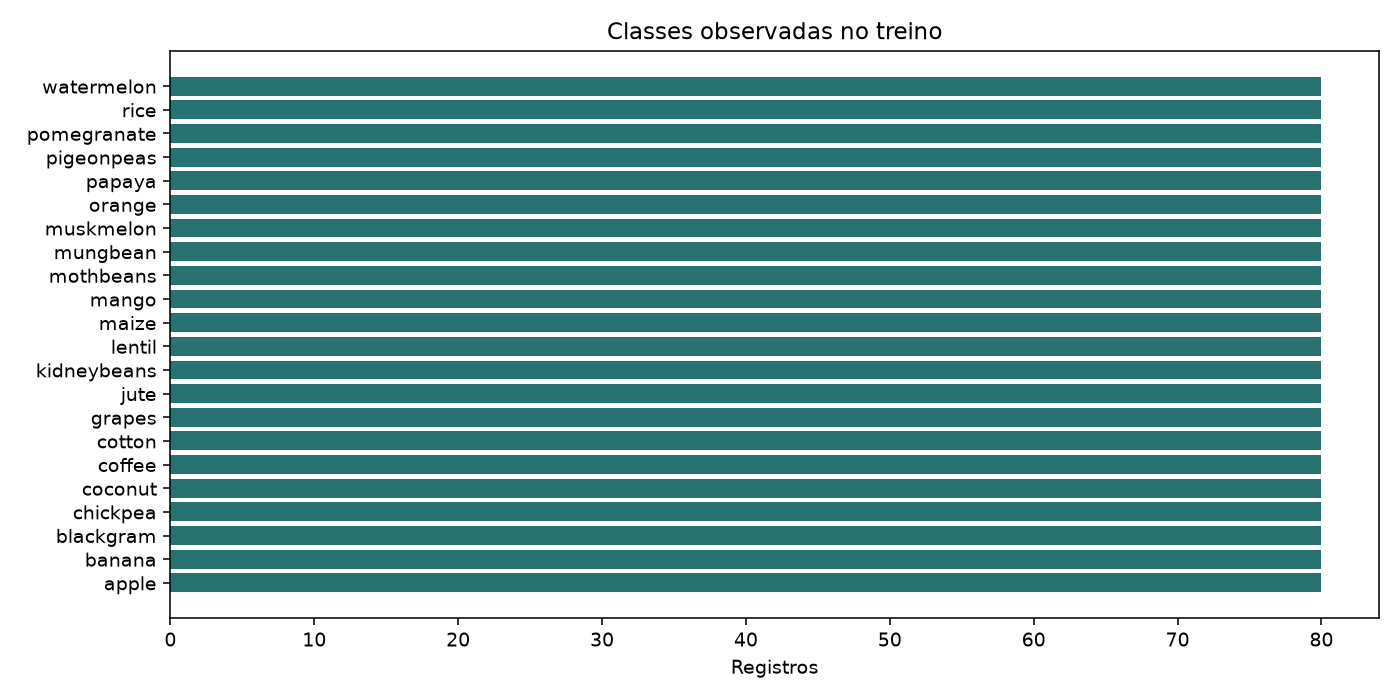

In [4]:
display(pd.DataFrame({name: {**stats_row(item), 'nulos': item['nulls']} for name, item in eda['summary'].items()}).T.round(2))
display(pd.DataFrame.from_dict(eda['class_distribution'], orient='index', columns=['contagem']))
assert len(eda['class_distribution']) == 22
assert set(eda['class_distribution'].values()) == {80}
display(Image(filename=str(ROOT / eda['figures']['class-distribution']), width=1000))

## Hipóteses exploratórias iniciais (HE1–HE4)

**Cronologia:** estas hipóteses foram formuladas em 2026-11-07, na revisão acadêmica, **após a EDA inicial já estar disponível**. São perguntas iniciais para organizar esta etapa do estudo; não eram hipóteses pré-registradas antes de observar os dados. Sua checagem é descritiva no treino utilizado para formulá-las. Não constitui confirmação independente, teste de significância ou evidência de desempenho fora dessa amostra. Uma futura investigação confirmatória precisaria de protocolo próprio e dados apropriados; isso não autoriza abrir o holdout.

As hipóteses delimitam relações solo/clima–cultura relevantes para a futura classificação. Para tornar a verificação explícita, cada regra abaixo pode ser contrariada pela ordem das medianas ou pelo sinal da correlação nos agregados da EDA. Os exemplos foram escolhidos nesta exploração e não representam todos os pares de culturas.

| Hipótese específica e regra descritiva | Evidência no treino e visualização | Resultado e limite |
|---|---|---|
| **HE1 — Solo:** a mediana de `N` de `cotton` é maior que a de `orange`. Checar `mediana(cotton) > mediana(orange)`. | Medianas 115,00 e 19,00; intervalos entre Q1 e Q3 107,00–126,00 e 9,00–29,25. Boxplot de `N` abaixo. | **Sustentada descritivamente** para esse par. A variável pode distinguir alguns perfis de rótulos; não implica necessidade de adubação nem separação de todas as classes. |
| **HE2 — Clima:** a mediana de `humidity` de `chickpea` é menor que a de `rice`. Checar `mediana(chickpea) < mediana(rice)`. | Medianas 16,64 e 82,16; Q1–Q3 15,34–18,27 e 81,00–83,47. Boxplot de `humidity`. | **Sustentada descritivamente**. O contraste indica associação nessa amostra, sem provar preferência fisiológica ou unidade percentual. |
| **HE3 — Clima:** a mediana de `rainfall` de `rice` é maior que a de `maize`. Checar `mediana(rice) > mediana(maize)`. | Medianas 233,42 e 84,23; faixas observadas 182,56–298,56 e 60,65–109,75. Boxplot de `rainfall`. | **Sustentada descritivamente**. As faixas desses dois rótulos não se sobrepõem no treino; isso não estabelece limites de precipitação para cultivo real. |
| **HE4 — Informação compartilhada:** `P` e `K` apresentam associação linear positiva no treino. Checar `r de Pearson(P,K) > 0`. | `r = 0,7360` na matriz e no heatmap de correlações. | **Sustentada descritivamente**. Há informação compartilhada; não prova equivalência, causalidade ou que uma variável possa ser eliminada sem perda. |

As conclusões individuais das sete variáveis abaixo também mostram contraexemplos de sobreposição entre classes, evitando transformar contrastes selecionados em regras universais de classificação.

## Distribuições, relações variável–cultura e correlações

Para cada variável: um parágrafo de interpretação, uma tabela compacta por cultura (mín., Q1, mediana, Q3 e máx., arredondados a 2 casas), o histograma e o boxplot por cultura gerados pela EDA. Relação ou correlação descritiva não demonstra causalidade nem desempenho preditivo.

### N — indicador de nitrogênio; unidade não confirmada

O histograma mostra a amplitude 0,00–140,00 e a mediana global 37,00; a metade central está em 21,00–85,00. No boxplot, `cotton` tem mediana 115,00 e Q1–Q3 107,00–126,00, enquanto `orange` tem 19,00 e 9,00–29,25. Esse contraste sustenta HE1 e justifica `N` como candidato para diferenciar perfis de solo associados a alguns rótulos.

A relevância é parcial: `rice` e `maize` têm medianas 80,00 e 76,00, com intervalos centrais 69,00–91,00 e 66,75–87,00 sobrepostos. Logo `N` isolado não fornece uma separação geral entre culturas. Não houve candidatos globais por IQR nessa variável; isso não certifica ausência de erros nem converte seus valores em dosagens agrícolas. Fonte: `summary.N`, `feature_class.N` e `outliers.features.N`.

,mín.,Q1,mediana,Q3,máx.
apple,0.0,10.75,24.5,30.25,40.0
banana,80.0,91.75,101.0,109.25,120.0
blackgram,20.0,28.75,41.0,50.00,59.0
chickpea,20.0,31.00,39.0,51.25,60.0
coconut,0.0,14.75,24.5,31.00,40.0
coffee,80.0,91.75,103.0,112.25,120.0
cotton,100.0,107.00,115.0,126.00,140.0
grapes,0.0,11.00,25.5,35.25,40.0
jute,60.0,68.50,77.5,89.00,100.0
kidneybeans,0.0,11.00,22.0,28.00,40.0


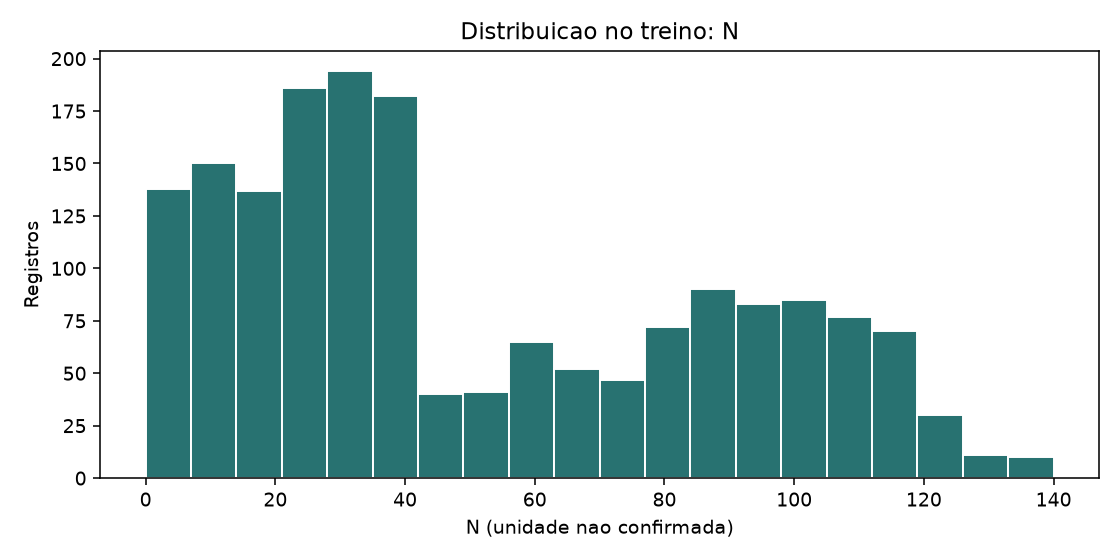

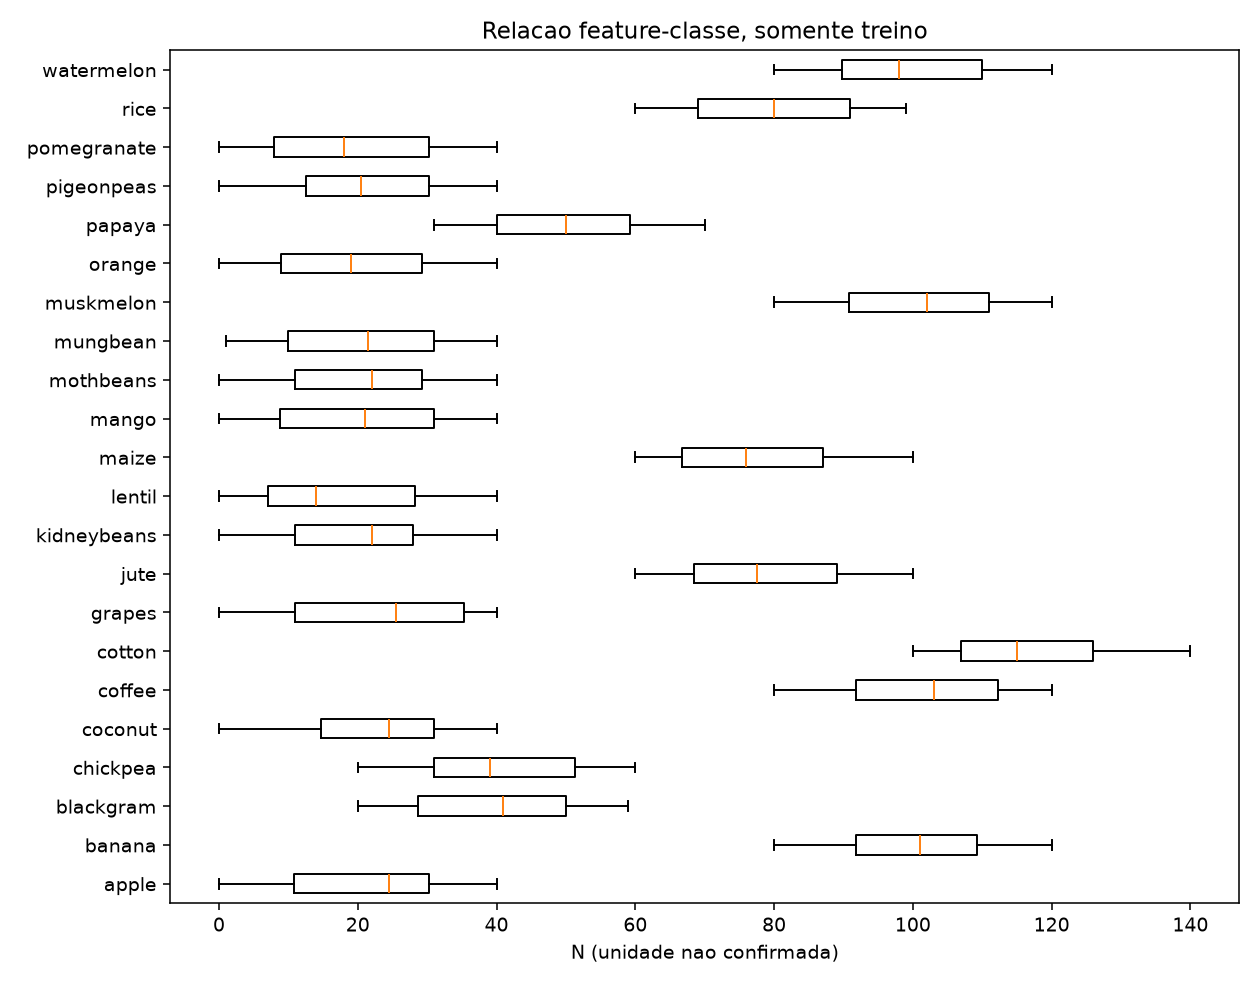

In [5]:
feature = 'N'
display(class_table(feature))
display(Image(filename=str(ROOT / eda['figures'][feature + '-distribution']), width=1000))
display(Image(filename=str(ROOT / eda['figures'][feature + '-class']), width=1000))

### P — indicador de fósforo; unidade não confirmada

A distribuição vai de 5,00–145,00, com mediana 51,00 e metade central 28,00–68,00. O boxplot identifica `apple` e `grapes` com medianas 137,00 e 133,00, frente a 16,00 em `orange`. Essa variação entre rótulos justifica manter `P` como indicador de solo candidato para a futura classificação.

`apple` e `grapes` apresentam Q1–Q3 125,75–142,00 e 125,00–139,00, amplamente sobrepostos: valores altos de `P` não distinguem esse par por si só. A correlação com `K` (0,7360) indica informação compartilhada, discutida em HE4, e exige cautela ao interpretar contribuições individuais. Os 108 candidatos IQR são observações extremas na distribuição agregada, sem erro agronômico comprovado; conservá-los evita descartar automaticamente perfis de classes. Fonte: `summary.P`, `feature_class.P`, `correlations` e `outliers.features.P`.

,mín.,Q1,mediana,Q3,máx.
apple,120.0,125.75,137.0,142.00,145.0
banana,70.0,75.00,81.5,88.00,95.0
blackgram,55.0,62.00,67.0,73.25,80.0
chickpea,55.0,61.75,68.0,73.25,80.0
coconut,5.0,8.75,15.0,25.25,30.0
coffee,15.0,23.00,29.0,35.00,40.0
cotton,35.0,40.00,46.0,52.00,60.0
grapes,120.0,125.00,133.0,139.00,145.0
jute,35.0,41.00,47.0,54.00,60.0
kidneybeans,55.0,60.00,67.0,75.00,80.0


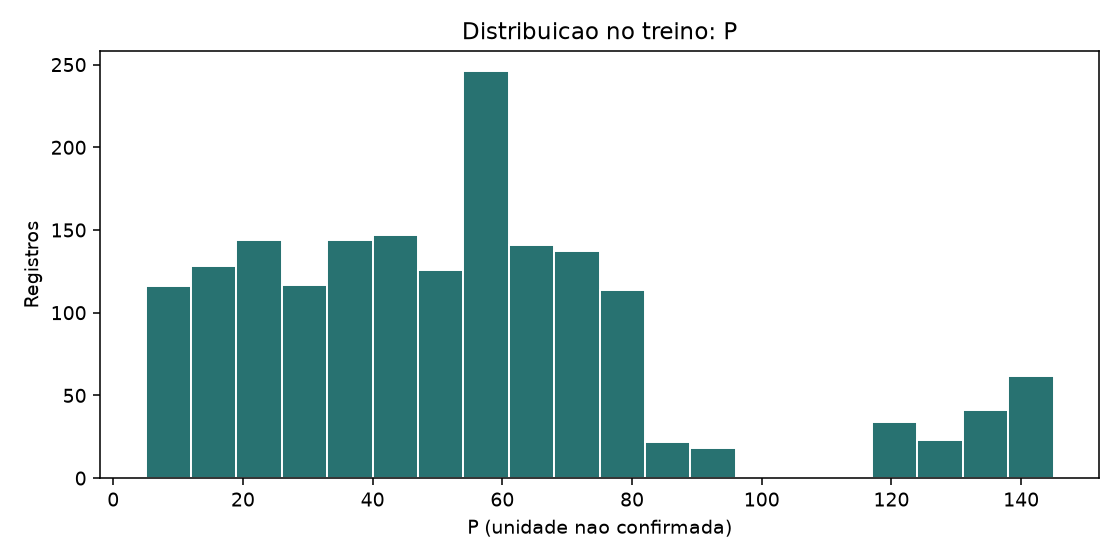

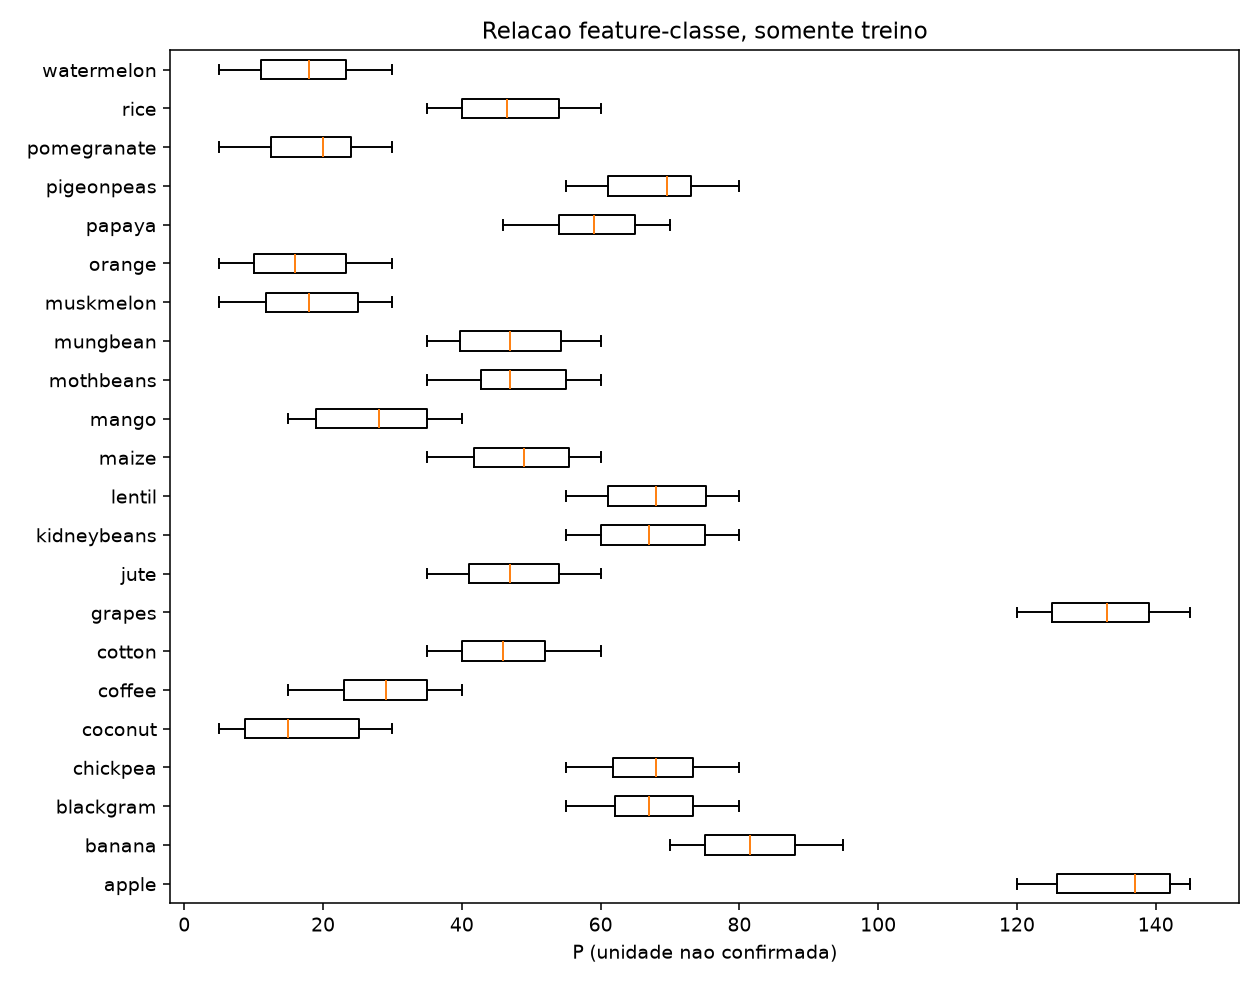

In [6]:
feature = 'P'
display(class_table(feature))
display(Image(filename=str(ROOT / eda['figures'][feature + '-distribution']), width=1000))
display(Image(filename=str(ROOT / eda['figures'][feature + '-class']), width=1000))

### K — indicador de potássio; unidade não confirmada

O histograma evidencia uma distribuição ampla (5,00–205,00) com mediana 32,00, Q1–Q3 20,00–49,00 e observações bem acima da região central. O boxplot permite localizar parte desse grupo: medianas de 200,00 em `apple` e 201,00 em `grapes`, comparadas a 19,50 em `maize`. Esse contraste justifica `K` como candidato relevante para distinguir grupos de rótulos.

Os intervalos centrais de `apple` e `grapes` coincidem em 197,00–203,00, mostrando que `K` não resolve a distinção entre essas classes. Seus 160 candidatos IQR não são automaticamente erros: a distribuição por classe mostra perfis altos que o critério global marca como extremos. A decisão de manter todas as observações preserva esses registros, e a correlação P–K não autoriza retirar uma dessas variáveis sem avaliação própria. Fonte: `summary.K`, `feature_class.K`, `correlations` e `outliers.features.K`.

,mín.,Q1,mediana,Q3,máx.
apple,195.0,197.00,200.0,203.00,205.0
banana,45.0,47.00,50.0,53.00,55.0
blackgram,15.0,16.00,19.0,22.00,25.0
chickpea,75.0,77.00,79.0,83.00,85.0
coconut,25.0,29.00,30.5,33.00,35.0
coffee,25.0,27.00,30.0,33.00,35.0
cotton,15.0,17.00,19.0,22.00,25.0
grapes,195.0,197.00,201.0,203.00,205.0
jute,35.0,37.00,40.0,43.00,45.0
kidneybeans,15.0,17.00,20.0,22.25,25.0


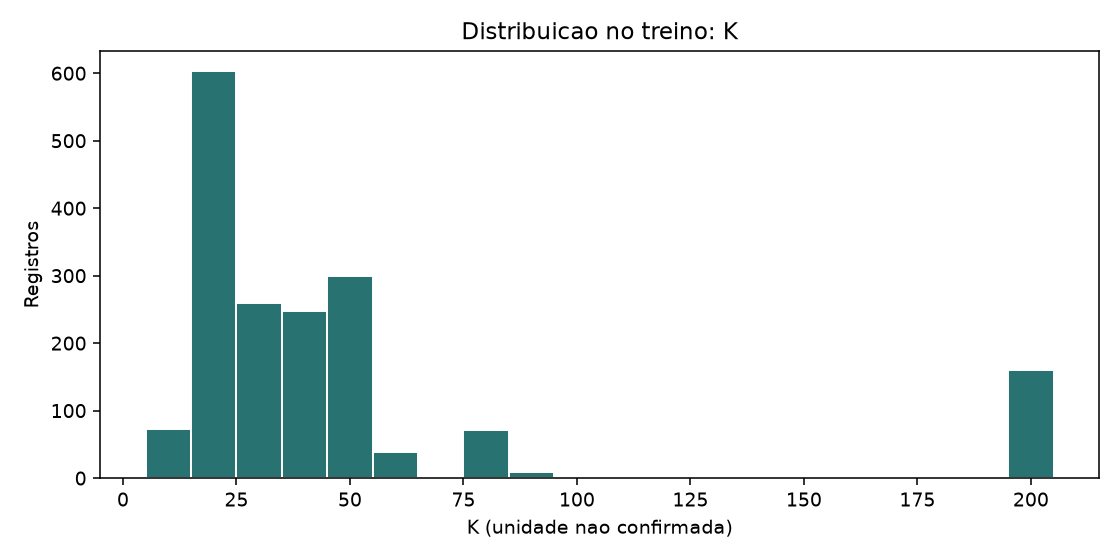

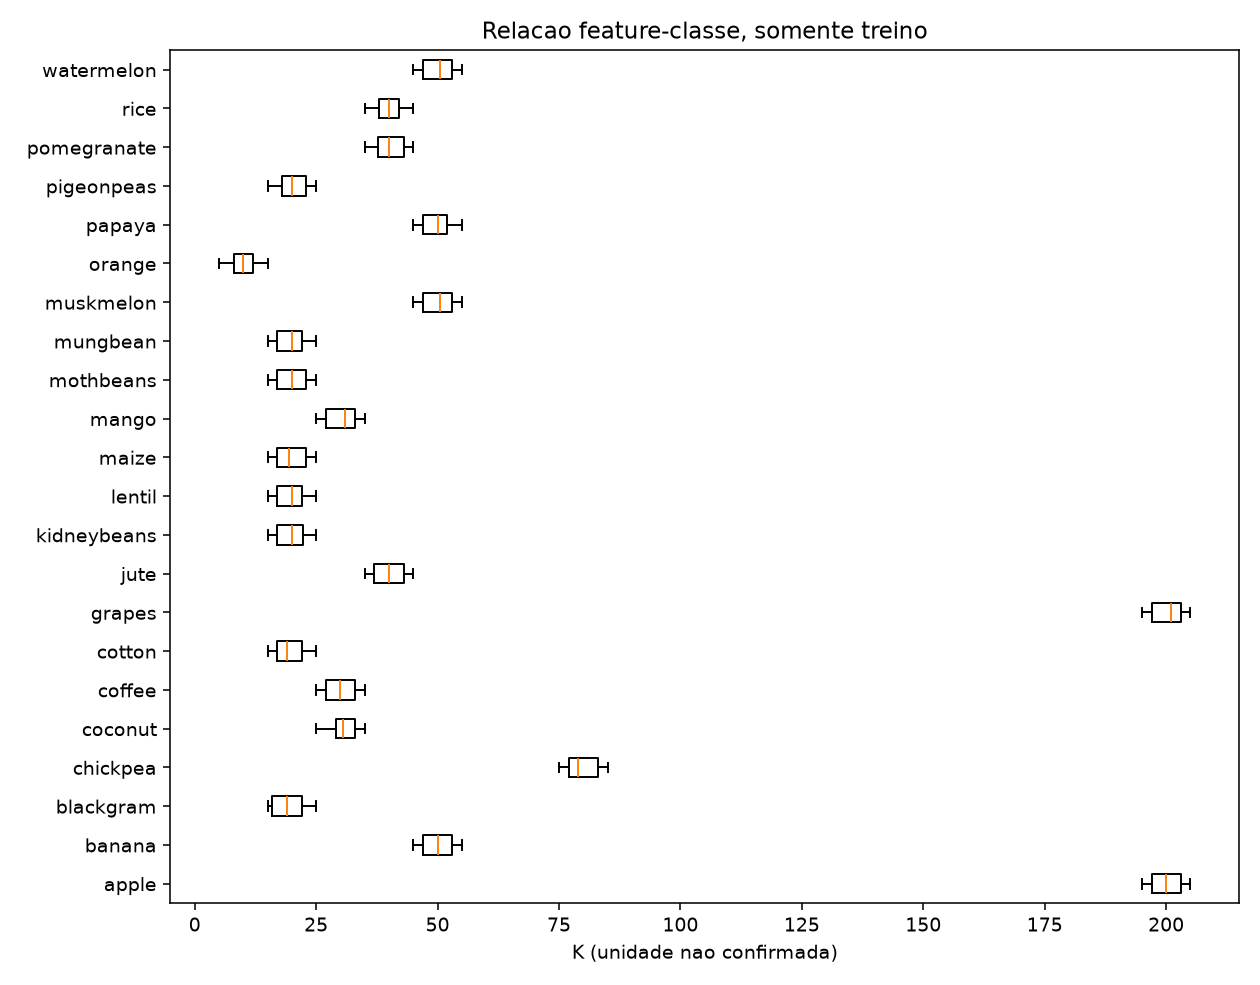

In [7]:
feature = 'K'
display(class_table(feature))
display(Image(filename=str(ROOT / eda['figures'][feature + '-distribution']), width=1000))
display(Image(filename=str(ROOT / eda['figures'][feature + '-class']), width=1000))

### temperature — indicador de temperatura; unidade não confirmada

A amplitude observada é 8,83–43,68, com mediana global 25,52 e Q1–Q3 22,78–28,55. O boxplot contrasta `chickpea` (mediana 18,89; Q1–Q3 17,93–19,74) e `muskmelon` (28,89; 27,84–29,34). Essa diferença justifica investigar a variável como dimensão climática associada aos rótulos.

O limite aparece em `rice` e `cotton`: medianas 23,81 e 23,84, com intervalos centrais 22,28–25,52 e 22,94–24,89 sobrepostos. A temperatura não é uma regra única para todas as culturas. Há 72 candidatos IQR; sem unidade, método e local confirmados, a amplitude não permite afirmar erro físico nem converter os valores em faixas térmicas de plantio. Fonte: `summary.temperature`, `feature_class.temperature` e `outliers.features.temperature`.

,mín.,Q1,mediana,Q3,máx.
apple,21.04,22.19,22.71,23.28,24.00
banana,25.01,26.32,27.54,28.67,29.91
blackgram,25.10,27.80,29.51,31.75,34.95
chickpea,17.02,17.93,18.89,19.74,21.00
coconut,25.01,26.17,27.39,28.51,29.87
coffee,23.11,24.23,25.66,26.99,27.92
cotton,22.00,22.94,23.84,24.89,25.99
grapes,8.83,16.34,24.32,31.16,41.95
jute,23.09,23.80,24.89,25.84,26.99
kidneybeans,15.33,18.74,20.12,22.69,24.90


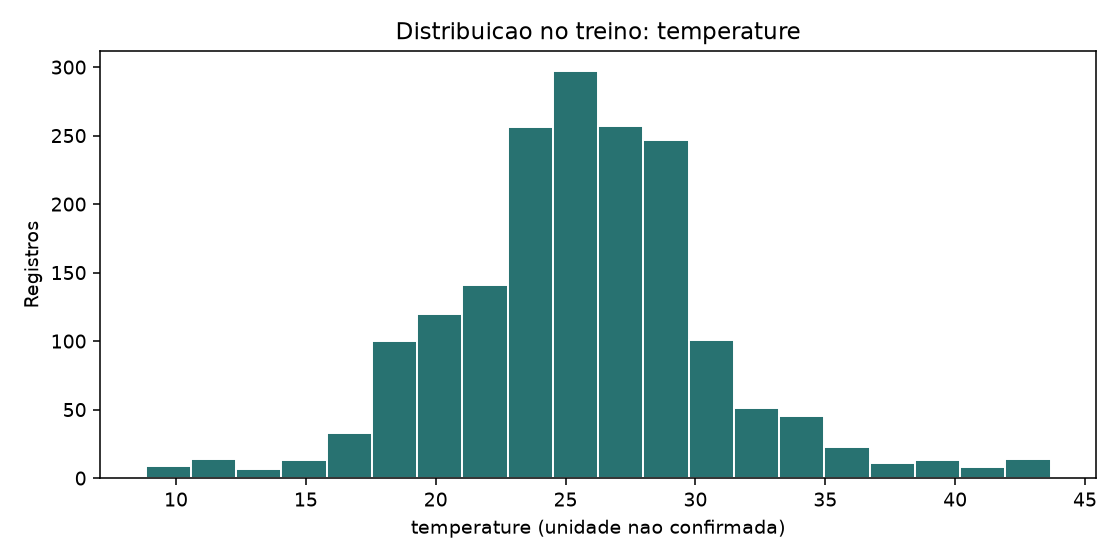

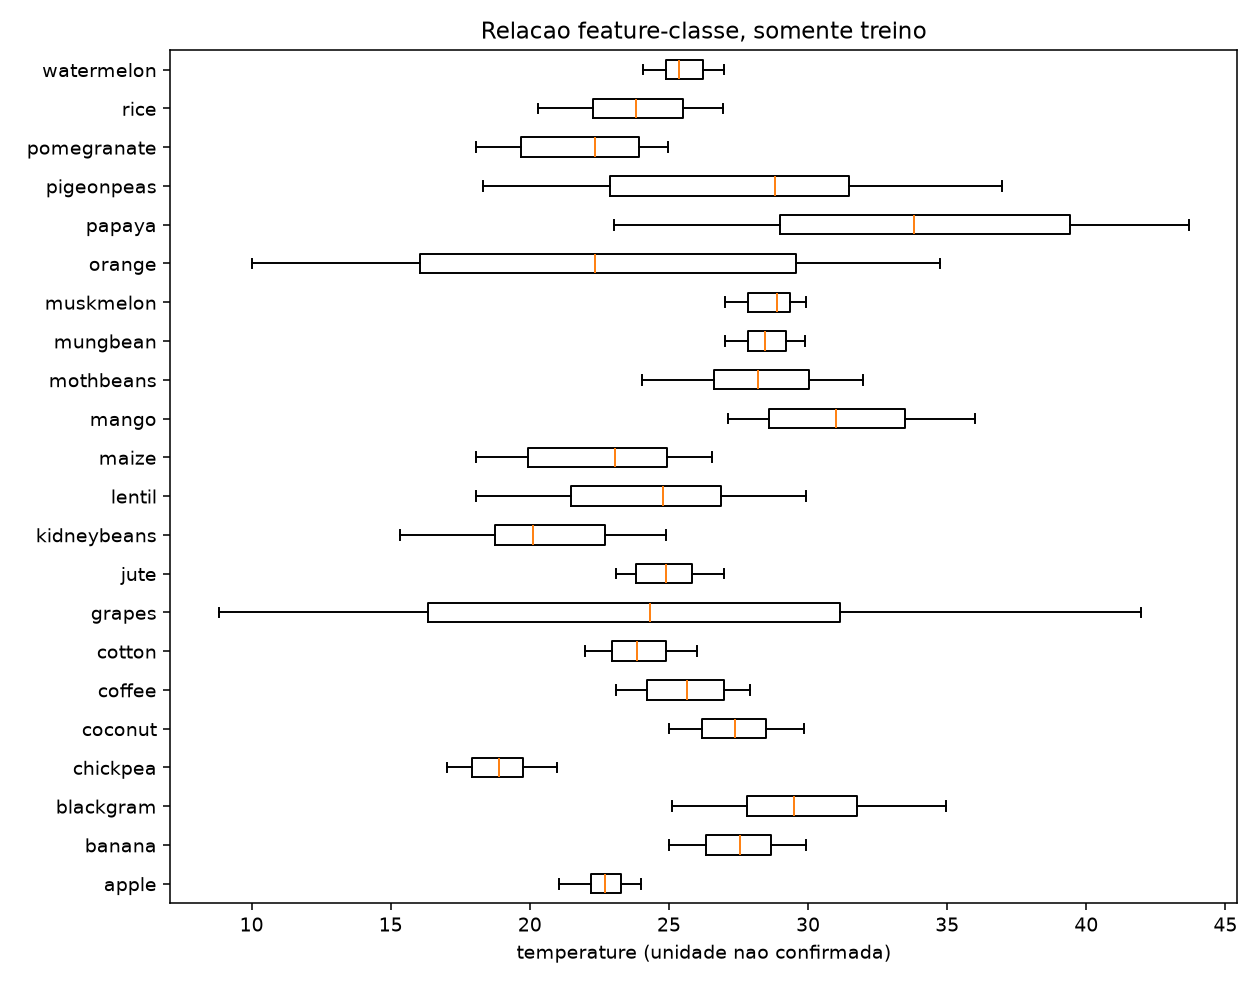

In [8]:
feature = 'temperature'
display(class_table(feature))
display(Image(filename=str(ROOT / eda['figures'][feature + '-distribution']), width=1000))
display(Image(filename=str(ROOT / eda['figures'][feature + '-class']), width=1000))

### humidity — indicador de umidade; unidade não confirmada

A distribuição apresenta mediana global 80,54, intervalo central 60,20–89,91 e amplitude 14,26–99,98. No boxplot, `chickpea` tem mediana 16,64 e Q1–Q3 15,34–18,27, abaixo de `rice` (82,16; 81,00–83,47). Essa evidência sustenta HE2 e justifica manter essa dimensão climática na investigação dos perfis de cultura.

A separação não se repete para todo par: `apple` e `orange` têm medianas 92,33 e 91,96, com Q1–Q3 90,96–93,47 e 91,10–93,38 sobrepostos. Portanto a variável pode contribuir em conjunto com outras, sem provar importância preditiva isolada. Há 24 candidatos IQR; não se assume que a escala represente umidade relativa em porcentagem. Fonte: `summary.humidity`, `feature_class.humidity` e `outliers.features.humidity`.

,mín.,Q1,mediana,Q3,máx.
apple,90.03,90.96,92.33,93.47,94.92
banana,75.03,78.31,80.45,82.97,84.98
blackgram,60.07,62.98,64.73,67.71,69.84
chickpea,14.26,15.34,16.64,18.27,19.97
coconut,90.02,92.69,94.77,96.76,99.98
coffee,50.05,53.43,57.45,63.01,69.95
cotton,75.01,77.07,80.38,82.53,84.88
grapes,80.02,80.91,81.65,82.79,83.98
jute,70.88,74.07,78.87,82.88,89.89
kidneybeans,18.09,19.84,21.35,23.48,24.97


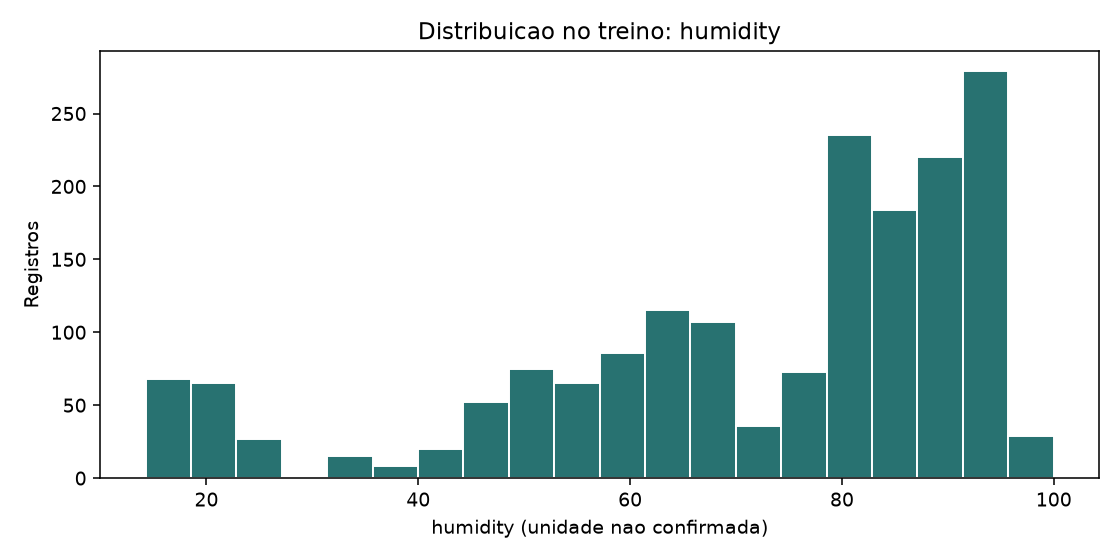

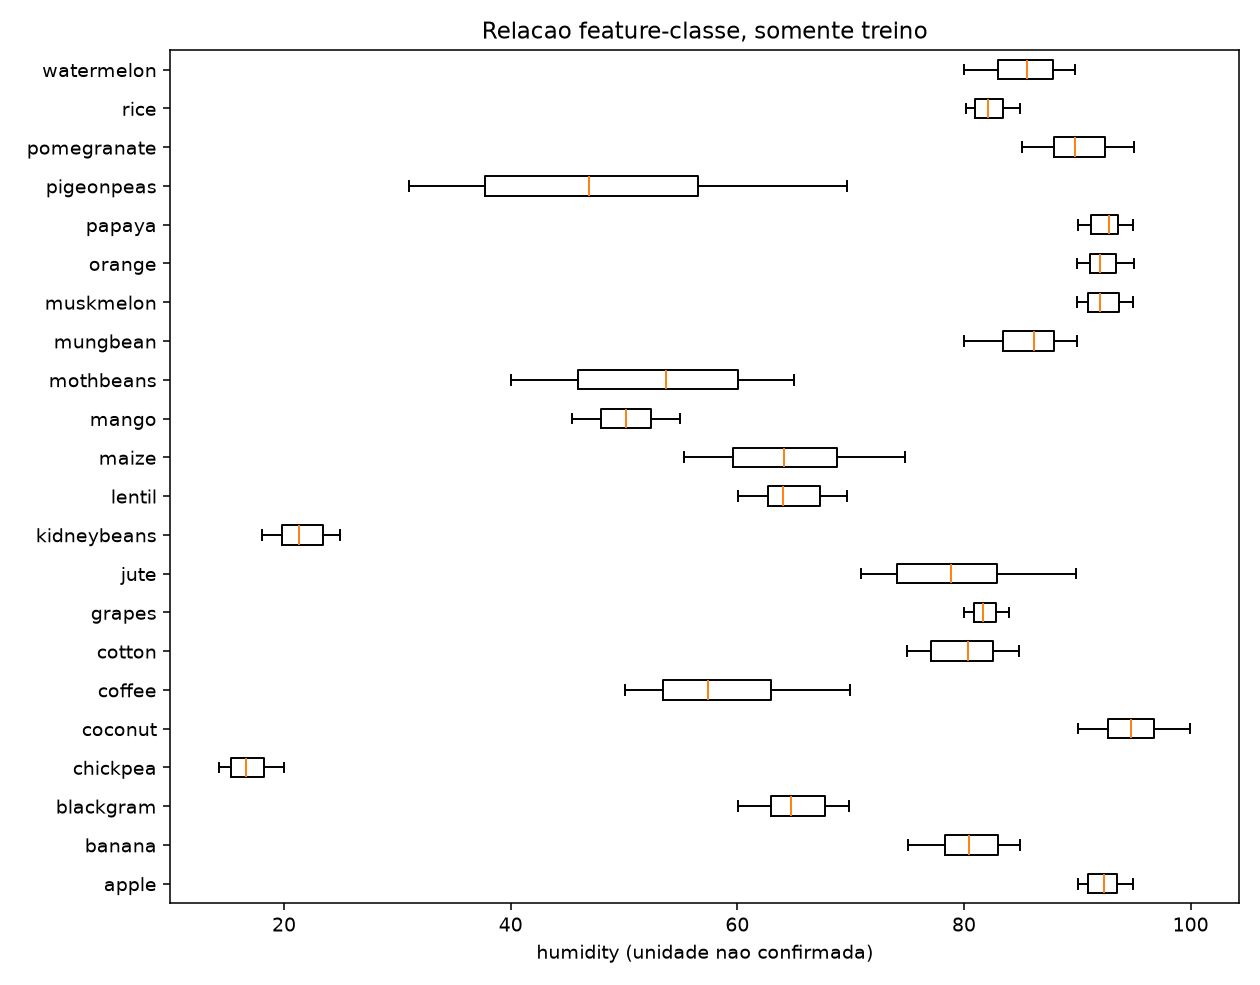

In [9]:
feature = 'humidity'
display(class_table(feature))
display(Image(filename=str(ROOT / eda['figures'][feature + '-distribution']), width=1000))
display(Image(filename=str(ROOT / eda['figures'][feature + '-class']), width=1000))

### ph — indicador de acidez no dicionário do projeto; escala/método não confirmados

A mediana global é 6,43, com Q1–Q3 5,96–6,93 e amplitude 3,50–9,94. O boxplot mostra `kidneybeans` com mediana 5,75 e Q1–Q3 5,64–5,86, frente a `chickpea` com 7,36 e 6,62–7,98. Esse contraste justifica explorar `ph` como característica de solo associada a determinados rótulos, mantendo-a entre as sete entradas.

A relevância tem limites: `apple` e `grapes` têm medianas 5,89 e 6,00, com intervalos 5,74–6,15 e 5,75–6,28 sobrepostos. Logo não há corte único demonstrado para classificar todas as culturas. Os 43 candidatos IQR são estatísticos; os extremos não autorizam prescrever correção do solo ou validar plausibilidade agronômica sem método de medição confirmado. Fonte: `summary.ph`, `feature_class.ph` e `outliers.features.ph`.

,mín.,Q1,mediana,Q3,máx.
apple,5.51,5.74,5.89,6.15,6.50
banana,5.51,5.74,5.92,6.21,6.49
blackgram,6.50,6.81,7.17,7.41,7.78
chickpea,5.99,6.62,7.36,7.98,8.87
coconut,5.50,5.71,5.98,6.22,6.47
coffee,6.02,6.42,6.78,7.14,7.49
cotton,5.80,6.41,6.92,7.43,7.99
grapes,5.51,5.75,6.00,6.28,6.50
jute,6.00,6.36,6.70,7.13,7.49
kidneybeans,5.50,5.64,5.75,5.86,6.00


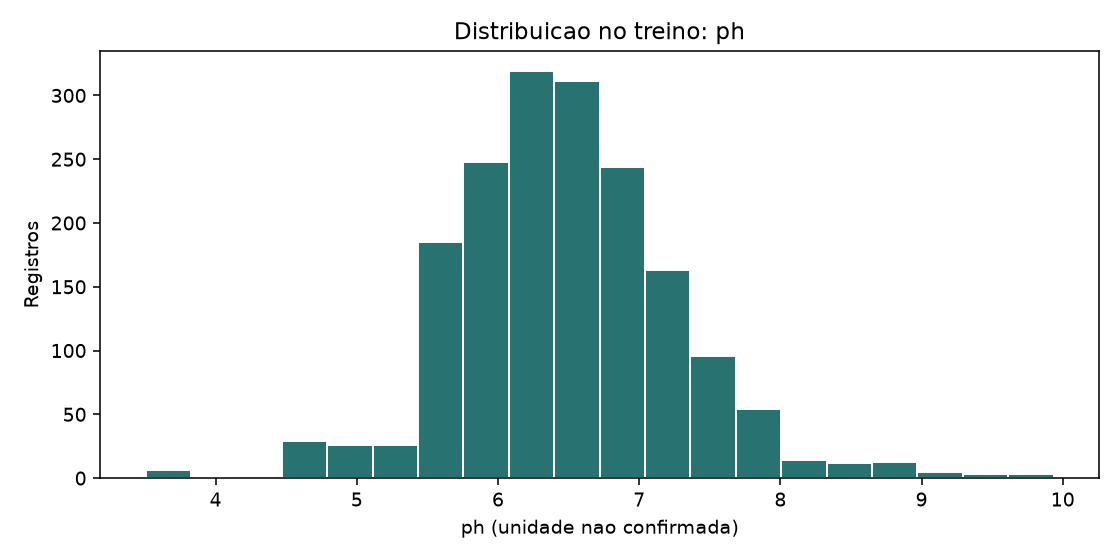

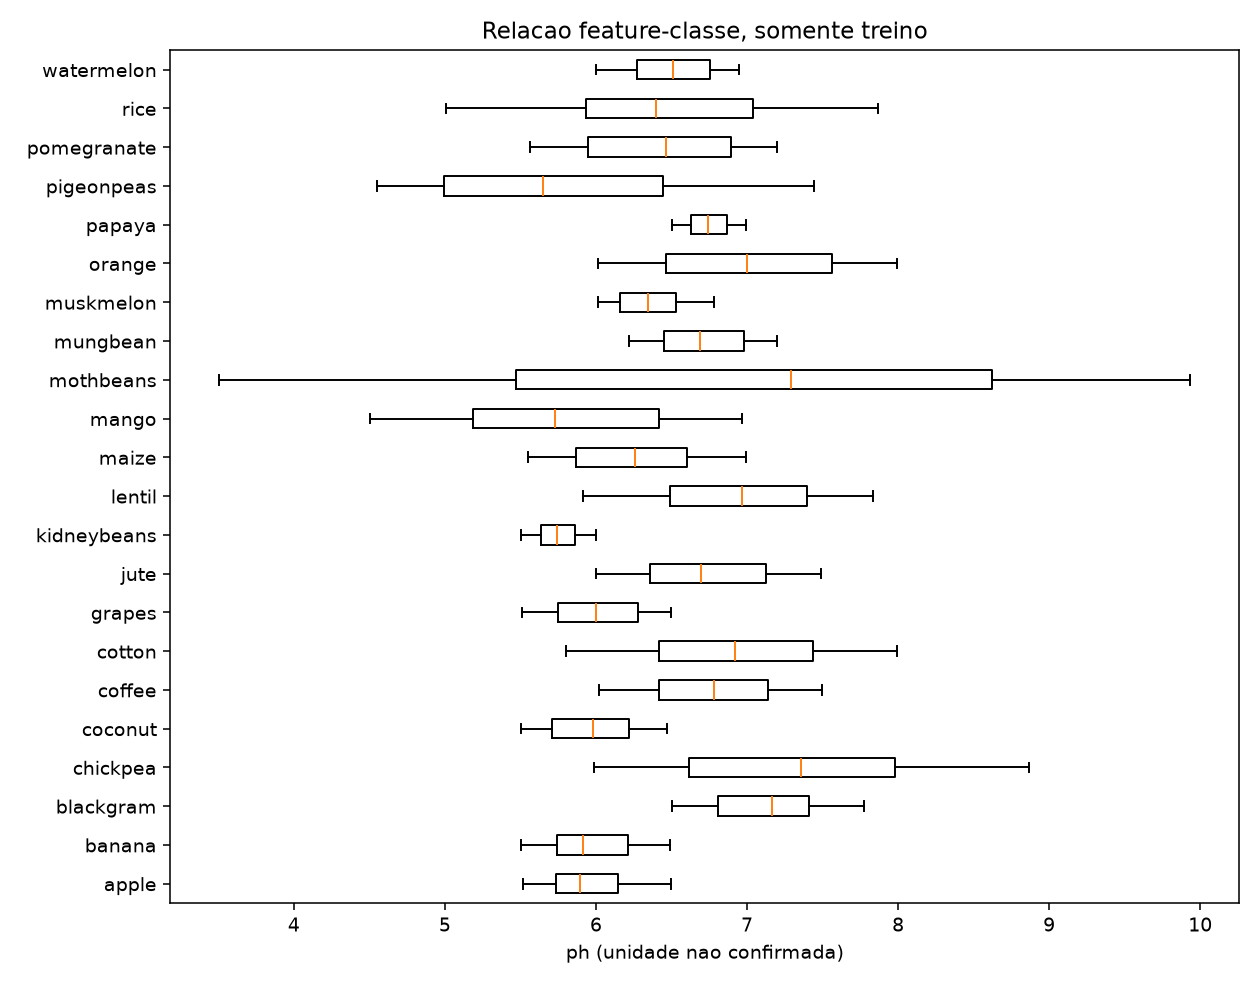

In [10]:
feature = 'ph'
display(class_table(feature))
display(Image(filename=str(ROOT / eda['figures'][feature + '-distribution']), width=1000))
display(Image(filename=str(ROOT / eda['figures'][feature + '-class']), width=1000))

### rainfall — indicador de precipitação; unidade e período não confirmados

A distribuição vai de 20,21–298,56, com mediana 94,77 e Q1–Q3 64,55–123,59. O boxplot mostra `rice` (mediana 233,42; faixa 182,56–298,56) frente a `maize` (84,23; 60,65–109,75). As faixas não se sobrepõem nesse treino, sustentando HE3 e justificando a precipitação como candidata para distinguir alguns perfis climáticos dos rótulos.

Outros pares permanecem semelhantes: `apple` e `orange` têm medianas 112,49 e 111,26, com Q1–Q3 105,66–117,95 e 106,70–115,62 sobrepostos. Assim, esse contraste não vira regra geral de recomendação. Há 82 candidatos IQR; não se assume que os valores estejam em milímetros ou correspondam a totais anuais, nem se infere disponibilidade de irrigação. Fonte: `summary.rainfall`, `feature_class.rainfall` e `outliers.features.rainfall`.

,mín.,Q1,mediana,Q3,máx.
apple,100.12,105.66,112.49,117.95,124.98
banana,90.11,96.47,105.25,112.09,119.85
blackgram,60.42,63.77,67.68,71.18,74.92
chickpea,65.11,74.35,79.23,85.41,94.78
coconut,131.09,148.70,171.85,202.35,225.63
coffee,115.16,137.46,156.42,178.72,199.47
cotton,60.65,71.22,80.66,90.50,99.93
grapes,65.01,67.01,69.65,71.61,74.82
jute,150.25,162.03,176.69,190.06,199.84
kidneybeans,60.28,87.51,107.40,128.53,149.74


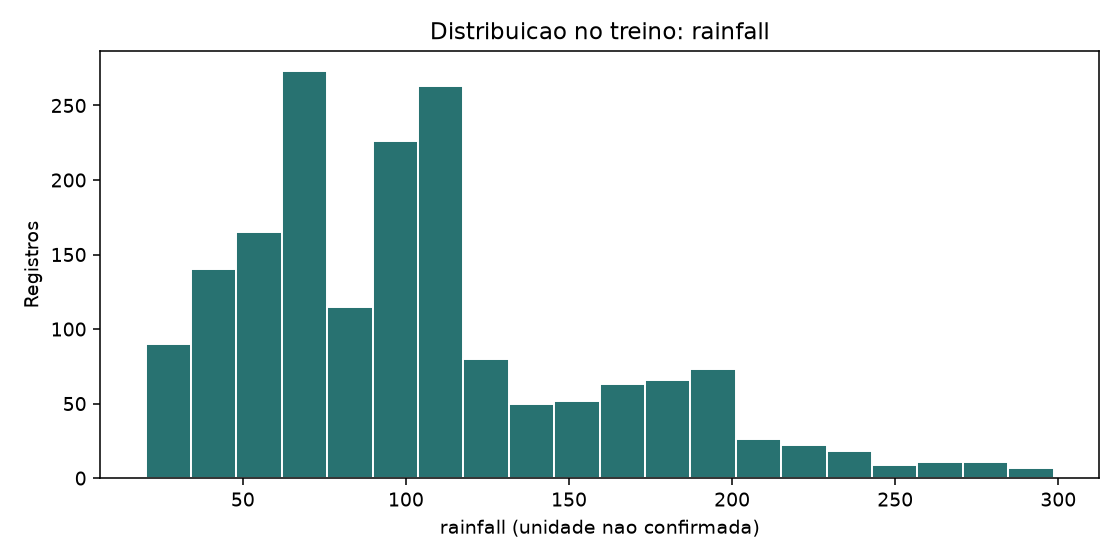

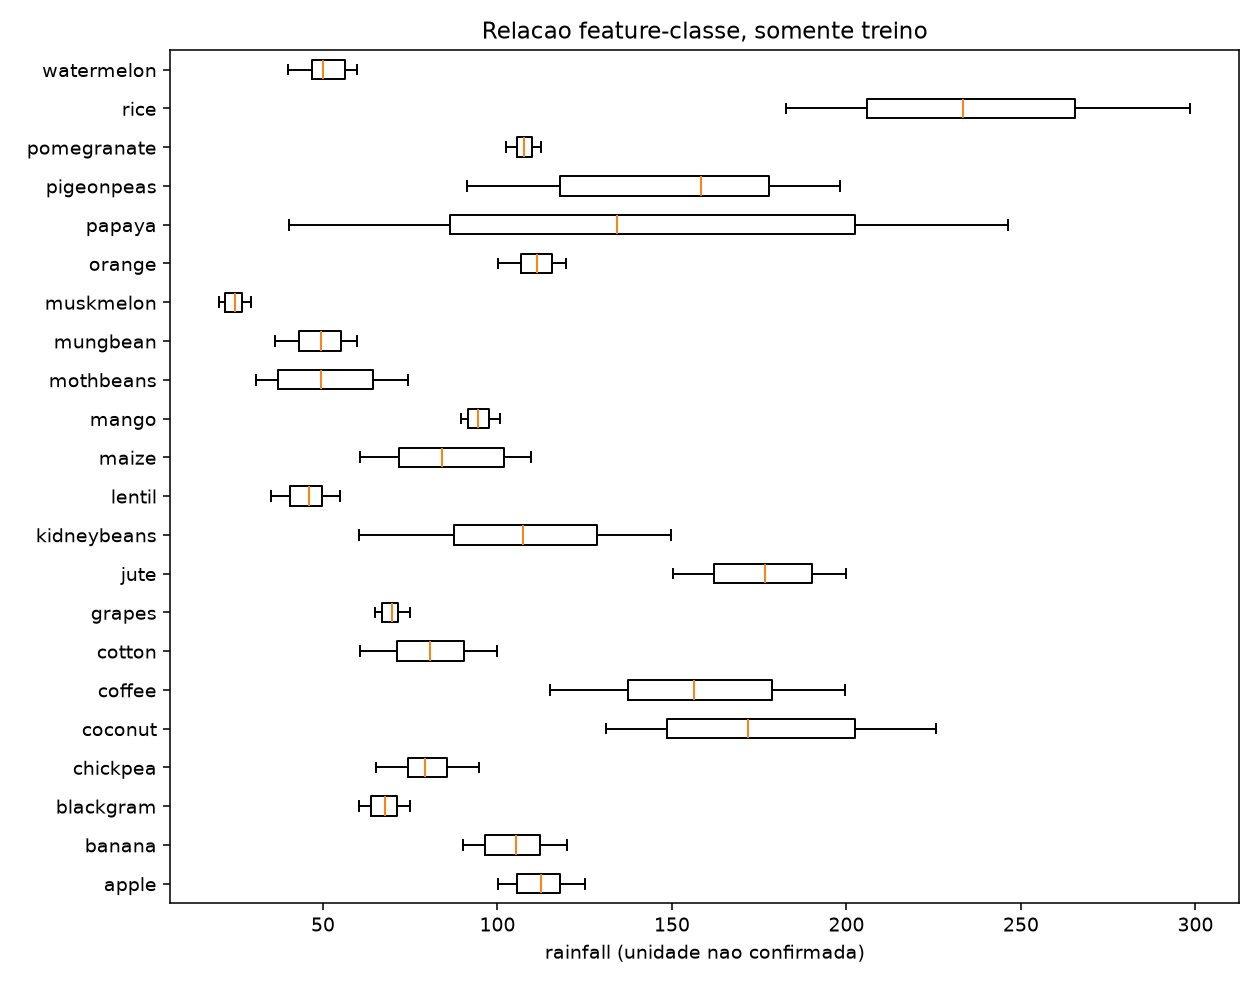

In [11]:
feature = 'rainfall'
display(class_table(feature))
display(Image(filename=str(ROOT / eda['figures'][feature + '-distribution']), width=1000))
display(Image(filename=str(ROOT / eda['figures'][feature + '-class']), width=1000))

,N,P,K,temperature,humidity,ph,rainfall
N,1.0000,-0.2294,-0.1347,0.0343,0.1942,0.0943,0.0660
P,-0.2294,1.0000,0.7360,-0.1083,-0.1187,-0.1333,-0.0680
K,-0.1347,0.7360,1.0000,-0.1416,0.1912,-0.1684,-0.0545
temperature,0.0343,-0.1083,-0.1416,1.0000,0.2027,-0.0335,-0.0283
humidity,0.1942,-0.1187,0.1912,0.2027,1.0000,-0.0123,0.0942
ph,0.0943,-0.1333,-0.1684,-0.0335,-0.0123,1.0000,-0.1058
rainfall,0.0660,-0.0680,-0.0545,-0.0283,0.0942,-0.1058,1.0000


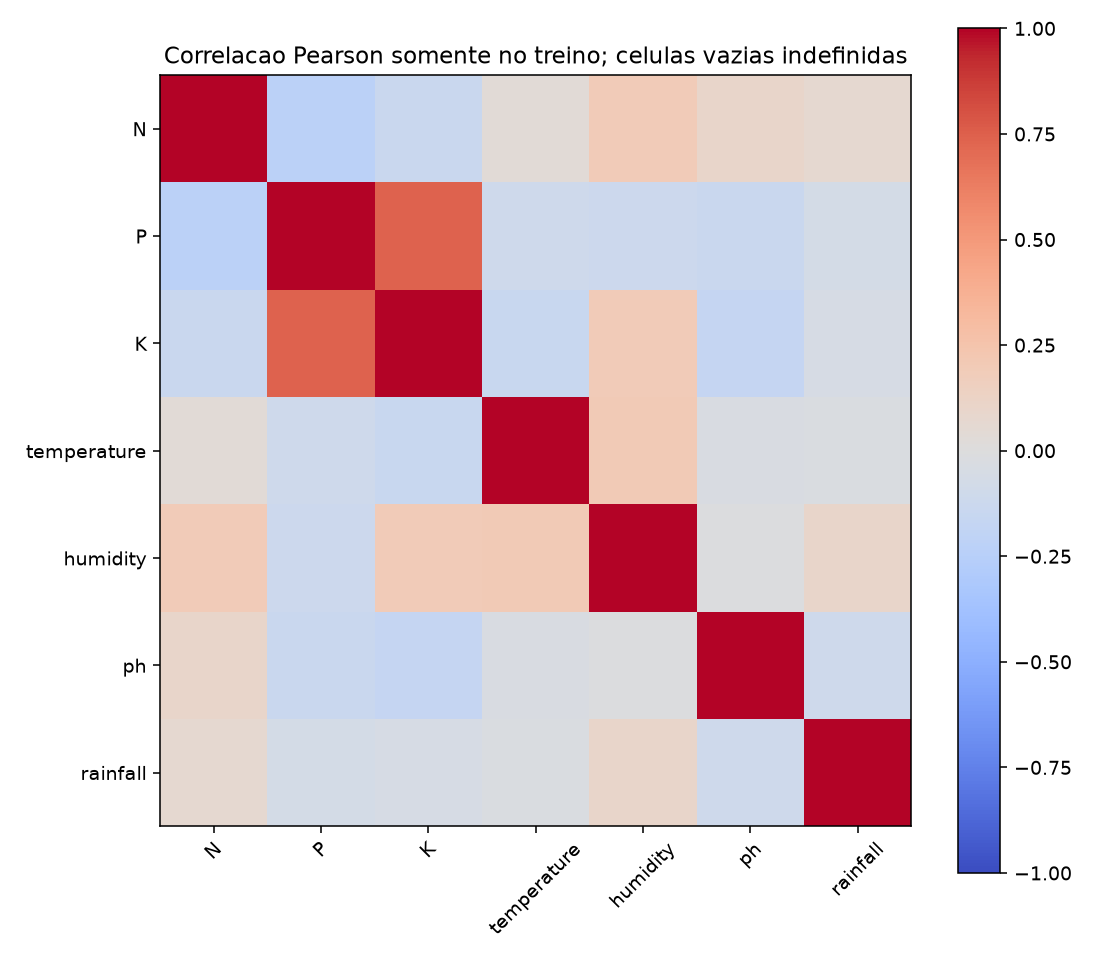

In [12]:
corr = eda['correlations']
display(pd.DataFrame(corr['matrix'], index=corr['feature_order'], columns=corr['feature_order']).round(4))
display(Image(filename=str(ROOT / eda['figures']['correlations']), width=1000))

## Interpretação conjunta das visualizações e variáveis relevantes

O gráfico de classes confirma 80 observações por rótulo no treino. Isso dá o mesmo suporte descritivo às 22 classes nesta análise, mas não demonstra frequência real ou representatividade fora da amostra. Os histogramas revelam escalas e assimetrias distintas; os boxplots por classe mostram que algumas diferenças globais correspondem a grupos de culturas, e não necessariamente a observações erradas.

No heatmap, a correlação linear de maior magnitude fora da diagonal é **P–K = 0,7360**, positiva. Ela sustenta HE4 e alerta para informação compartilhada; não demonstra equivalência de variáveis nem sua contribuição condicional ao alvo. Os demais pares têm magnitudes menores (por exemplo, N–P = −0,2294 e temperature–humidity = 0,2027). Correlação entre entradas não mede associação com um alvo categórico nem importância preditiva. Correlação baixa entre duas entradas também não prova inutilidade ou independência estatística.

**Identificação e decisão sobre relevância:** `N`, `P`, `K` e `ph` descrevem dimensões de solo; `temperature`, `humidity` e `rainfall` descrevem dimensões climáticas no problema. Cada uma apresenta ao menos um contraste por classe explicitado acima, o que justifica sua inclusão como variável candidata. Para todas foram também apresentados pares de classes sobrepostos: nenhuma foi demonstrada como condição suficiente para recomendar uma cultura. Mantêm-se as sete entradas para investigação, sem ranking de importância, seleção automática ou exclusão baseada em correlação global. `label` é a variável resposta e não entra nas features.

Essa justificativa é exploratória e condicionada ao dataset. A utilidade preditiva conjunta das sete variáveis é avaliada no primeiro experimento (EXP-001), mais adiante. As unidades/métodos desconhecidos limitam a interpretação física. O conjunto de teste reservado não participou das análises, hipóteses ou decisões.

## Valores extremos: análise e decisão

O detector marca como candidato a extremo o valor abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR (quantis lineares, desigualdade estrita). Para cada variável abaixo aparecem os limites e a contagem de candidatos e, em seguida, o efeito hipotético de três cenários: manter, limitar os valores aos limites (*clipping*) e remover os candidatos. Nenhum cenário foi aplicado ao treino. Ser candidato estatístico não prova erro, e a plausibilidade agronômica segue desconhecida.

**Decisão:** manter todas as 1760 observações, sem limitar nem remover valores, conforme a política aprovada e registrada em [`outlier-policy.json`](../reports/data/outlier-policy.json). Os limites IQR da EDA não são reaproveitados como parâmetros antes da validação cruzada.

### Decisão por variável: N

In [13]:
feature = 'N'
record = outliers['features'][feature]
display(pd.DataFrame([{'Q1': record['q1']['value'], 'Q3': record['q3']['value'], 'limite inferior': record['lower']['value'],
                       'limite superior': record['upper']['value'], 'candidatos': record['candidate_count']}], index=[feature]))
scenarios = {SCENARIOS.get(name, name): {'linhas': result['n_rows'], 'culturas': sum(count > 0 for count in result['class_distribution'].values()),
                                         **stats_row(result['summary'][feature])} for name, result in record['comparison']['scenarios'].items()}
display(pd.DataFrame.from_dict(scenarios, orient='index').round(2))
display(Markdown('**Decisão: manter** — ' + policy['features'][feature]['justification']))

,Q1,Q3,limite inferior,limite superior,candidatos
N,21.0,85.0,-75.0,181.0,0


,linhas,culturas,mín.,Q1,mediana,Q3,máx.
manter,1760,22,0.0,21.0,37.0,85.0,140.0
limitar (clipping),1760,22,0.0,21.0,37.0,85.0,140.0
remover candidatos,1760,22,0.0,21.0,37.0,85.0,140.0


**Decisão: manter** — Nenhum candidato IQR observado; nao ha tratamento indicado pelo detector. S8 aprova preservar todas as 1760 observacoes.

### Decisão por variável: P

In [14]:
feature = 'P'
record = outliers['features'][feature]
display(pd.DataFrame([{'Q1': record['q1']['value'], 'Q3': record['q3']['value'], 'limite inferior': record['lower']['value'],
                       'limite superior': record['upper']['value'], 'candidatos': record['candidate_count']}], index=[feature]))
scenarios = {SCENARIOS.get(name, name): {'linhas': result['n_rows'], 'culturas': sum(count > 0 for count in result['class_distribution'].values()),
                                         **stats_row(result['summary'][feature])} for name, result in record['comparison']['scenarios'].items()}
display(pd.DataFrame.from_dict(scenarios, orient='index').round(2))
display(Markdown('**Decisão: manter** — ' + policy['features'][feature]['justification']))

,Q1,Q3,limite inferior,limite superior,candidatos
P,28.0,68.0,-32.0,128.0,108


,linhas,culturas,mín.,Q1,mediana,Q3,máx.
manter,1760,22,5.0,28.0,51.0,68.0,145.0
limitar (clipping),1760,22,5.0,28.0,51.0,68.0,128.0
remover candidatos,1652,22,5.0,27.0,48.0,64.0,128.0


**Decisão: manter** — 108 candidatos estatisticos nao comprovam erro agronomico; unidades nao confirmadas. Remocao hipotetica deixaria 1652 registros e 22 classes; clipping altera valores sem erro de medicao demonstrado. S8 aprova preservar todas as 1760 observacoes.

### Decisão por variável: K

In [15]:
feature = 'K'
record = outliers['features'][feature]
display(pd.DataFrame([{'Q1': record['q1']['value'], 'Q3': record['q3']['value'], 'limite inferior': record['lower']['value'],
                       'limite superior': record['upper']['value'], 'candidatos': record['candidate_count']}], index=[feature]))
scenarios = {SCENARIOS.get(name, name): {'linhas': result['n_rows'], 'culturas': sum(count > 0 for count in result['class_distribution'].values()),
                                         **stats_row(result['summary'][feature])} for name, result in record['comparison']['scenarios'].items()}
display(pd.DataFrame.from_dict(scenarios, orient='index').round(2))
display(Markdown('**Decisão: manter** — ' + policy['features'][feature]['justification']))

,Q1,Q3,limite inferior,limite superior,candidatos
K,20.0,49.0,-23.5,92.5,160


,linhas,culturas,mín.,Q1,mediana,Q3,máx.
manter,1760,22,5.0,20.0,32.0,49.0,205.0
limitar (clipping),1760,22,5.0,20.0,32.0,49.0,92.5
remover candidatos,1600,20,5.0,20.0,29.0,45.0,85.0


**Decisão: manter** — 160 candidatos estatisticos nao comprovam erro agronomico; unidades nao confirmadas. Remocao hipotetica deixaria 1600 registros e 20 classes; clipping altera valores sem erro de medicao demonstrado. S8 aprova preservar todas as 1760 observacoes.

### Decisão por variável: temperature

In [16]:
feature = 'temperature'
record = outliers['features'][feature]
display(pd.DataFrame([{'Q1': record['q1']['value'], 'Q3': record['q3']['value'], 'limite inferior': record['lower']['value'],
                       'limite superior': record['upper']['value'], 'candidatos': record['candidate_count']}], index=[feature]))
scenarios = {SCENARIOS.get(name, name): {'linhas': result['n_rows'], 'culturas': sum(count > 0 for count in result['class_distribution'].values()),
                                         **stats_row(result['summary'][feature])} for name, result in record['comparison']['scenarios'].items()}
display(pd.DataFrame.from_dict(scenarios, orient='index').round(2))
display(Markdown('**Decisão: manter** — ' + policy['features'][feature]['justification']))

,Q1,Q3,limite inferior,limite superior,candidatos
temperature,22.782207,28.550513,14.129748,37.202971,72


,linhas,culturas,mín.,Q1,mediana,Q3,máx.
manter,1760,22,8.83,22.78,25.52,28.55,43.68
limitar (clipping),1760,22,14.13,22.78,25.52,28.55,37.20
remover candidatos,1688,22,14.34,22.91,25.50,28.30,37.13


**Decisão: manter** — 72 candidatos estatisticos nao comprovam erro agronomico; unidades nao confirmadas. Remocao hipotetica deixaria 1688 registros e 22 classes; clipping altera valores sem erro de medicao demonstrado. S8 aprova preservar todas as 1760 observacoes.

### Decisão por variável: humidity

In [17]:
feature = 'humidity'
record = outliers['features'][feature]
display(pd.DataFrame([{'Q1': record['q1']['value'], 'Q3': record['q3']['value'], 'limite inferior': record['lower']['value'],
                       'limite superior': record['upper']['value'], 'candidatos': record['candidate_count']}], index=[feature]))
scenarios = {SCENARIOS.get(name, name): {'linhas': result['n_rows'], 'culturas': sum(count > 0 for count in result['class_distribution'].values()),
                                         **stats_row(result['summary'][feature])} for name, result in record['comparison']['scenarios'].items()}
display(pd.DataFrame.from_dict(scenarios, orient='index').round(2))
display(Markdown('**Decisão: manter** — ' + policy['features'][feature]['justification']))

,Q1,Q3,limite inferior,limite superior,candidatos
humidity,60.195432,89.908373,15.62602,134.477785,24


,linhas,culturas,mín.,Q1,mediana,Q3,máx.
manter,1760,22,14.26,60.20,80.54,89.91,99.98
limitar (clipping),1760,22,15.63,60.20,80.54,89.91,99.98
remover candidatos,1736,22,15.77,60.69,80.68,90.02,99.98


**Decisão: manter** — 24 candidatos estatisticos nao comprovam erro agronomico; unidades nao confirmadas. Remocao hipotetica deixaria 1736 registros e 22 classes; clipping altera valores sem erro de medicao demonstrado. S8 aprova preservar todas as 1760 observacoes.

### Decisão por variável: ph

In [18]:
feature = 'ph'
record = outliers['features'][feature]
display(pd.DataFrame([{'Q1': record['q1']['value'], 'Q3': record['q3']['value'], 'limite inferior': record['lower']['value'],
                       'limite superior': record['upper']['value'], 'candidatos': record['candidate_count']}], index=[feature]))
scenarios = {SCENARIOS.get(name, name): {'linhas': result['n_rows'], 'culturas': sum(count > 0 for count in result['class_distribution'].values()),
                                         **stats_row(result['summary'][feature])} for name, result in record['comparison']['scenarios'].items()}
display(pd.DataFrame.from_dict(scenarios, orient='index').round(2))
display(Markdown('**Decisão: manter** — ' + policy['features'][feature]['justification']))

,Q1,Q3,limite inferior,limite superior,candidatos
ph,5.955924,6.93173,4.492216,8.395438,43


,linhas,culturas,mín.,Q1,mediana,Q3,máx.
manter,1760,22,3.50,5.96,6.43,6.93,9.94
limitar (clipping),1760,22,4.49,5.96,6.43,6.93,8.40
remover candidatos,1717,22,4.51,5.95,6.42,6.90,8.38


**Decisão: manter** — 43 candidatos estatisticos nao comprovam erro agronomico; unidades nao confirmadas. Remocao hipotetica deixaria 1717 registros e 22 classes; clipping altera valores sem erro de medicao demonstrado. S8 aprova preservar todas as 1760 observacoes.

### Decisão por variável: rainfall

In [19]:
feature = 'rainfall'
record = outliers['features'][feature]
display(pd.DataFrame([{'Q1': record['q1']['value'], 'Q3': record['q3']['value'], 'limite inferior': record['lower']['value'],
                       'limite superior': record['upper']['value'], 'candidatos': record['candidate_count']}], index=[feature]))
scenarios = {SCENARIOS.get(name, name): {'linhas': result['n_rows'], 'culturas': sum(count > 0 for count in result['class_distribution'].values()),
                                         **stats_row(result['summary'][feature])} for name, result in record['comparison']['scenarios'].items()}
display(pd.DataFrame.from_dict(scenarios, orient='index').round(2))
display(Markdown('**Decisão: manter** — ' + policy['features'][feature]['justification']))

,Q1,Q3,limite inferior,limite superior,candidatos
rainfall,64.551686,123.592008,-24.008797,212.15249,82


,linhas,culturas,mín.,Q1,mediana,Q3,máx.
manter,1760,22,20.21,64.55,94.77,123.59,298.56
limitar (clipping),1760,22,20.21,64.55,94.77,123.59,212.15
remover candidatos,1678,22,20.21,63.54,91.98,116.81,211.85


**Decisão: manter** — 82 candidatos estatisticos nao comprovam erro agronomico; unidades nao confirmadas. Remocao hipotetica deixaria 1678 registros e 22 classes; clipping altera valores sem erro de medicao demonstrado. S8 aprova preservar todas as 1760 observacoes.

## Pré-processamento: decisões e alternativas

- **Escalonamento:** `StandardScaler` para a regressão logística e o MLP; nenhum escalonamento para os modelos de árvore. O `MinMaxScaler` foi considerado como alternativa e não foi selecionado.
- **Imputação:** não indicada, pois não há nulos; a validação de entrada recusa nulos em vez de ocultá-los.
- **Outras transformações:** normalização por linha e transformações log ou potência não têm justificativa e não foram aplicadas. Com sete colunas numéricas de tratamento uniforme, um `ColumnTransformer` não é necessário.
- **Alvo:** `label` fica fora das entradas; a codificação dos rótulos acontece na etapa de modelagem.
- **Sem vazamento:** o pré-processador é um `Pipeline` (validação de nomes, ordem e tipos das colunas, seguida do escalonamento). Na validação cruzada ele é ajustado só no treino de cada fold, e o fold de validação apenas o transforma. Estatísticas da EDA não pré-ajustam nada.

A célula abaixo constrói as três variantes e confirma que nenhuma está ajustada; ela não ajusta nada.

In [20]:
preprocessors = {choice: build_preprocessor(scaling=choice) for choice in ['none', 'standard', 'minmax']}
for choice, pipeline in preprocessors.items():
    assert not hasattr(pipeline.named_steps['validate'], 'n_features_in_')
    assert not hasattr(pipeline.named_steps['scaling'], 'n_features_in_')
    display(Markdown('**Pré-processador não ajustado: ' + choice + '**'))
    print(pipeline.get_params(deep=False))

**Pré-processador não ajustado: none**

{'memory': None, 'steps': [('validate', _FeatureValidator()), ('scaling', 'passthrough')], 'transform_input': None, 'verbose': False}


**Pré-processador não ajustado: standard**

{'memory': None, 'steps': [('validate', _FeatureValidator()), ('scaling', StandardScaler())], 'transform_input': None, 'verbose': False}


**Pré-processador não ajustado: minmax**

{'memory': None, 'steps': [('validate', _FeatureValidator()), ('scaling', MinMaxScaler())], 'transform_input': None, 'verbose': False}


## Metodologia

Decisões fixadas antes do primeiro experimento, todas aplicadas **somente ao treino** (1760 observações). Protocolo completo: [EXP-001](../reports/experiments/EXP-001.md), seções 2 e 3.

| Decisão | Escolha | Por quê |
|---|---|---|
| Tratamento dos dados | Nenhuma remoção ou limitação de valores extremos; sem imputação (não há nulos) | Os extremos caracterizam culturas específicas e não são erros comprovados (seção de valores extremos) |
| Escalonamento | `StandardScaler` só na regressão logística e no MLP, ajustado dentro de cada fold; nenhum nos modelos de árvore | Modelos lineares e redes neurais são sensíveis à escala; árvores não. Ajustar por fold evita vazamento de informação do fold de validação |
| Baseline | `DummyClassifier` (`most_frequent`: sempre prevê a mesma classe) | Mostra o desempenho de um modelo que não aprende nada com as variáveis |
| Modelos candidatos | Regressão logística, árvore de decisão, Random Forest, XGBoost, LightGBM e MLP, com hiperparâmetros fixados antes da execução (em geral, os padrões das bibliotecas) | Cobrem famílias diferentes: linear, árvore, ensembles de árvores e rede neural |
| Métrica principal | F1 macro; também precisão e recall (macro e weighted) | Dá o mesmo peso às 22 culturas, e o F1 equilibra precisão e recall |
| Validação | Validação cruzada estratificada (`StratifiedKFold`), 5 folds embaralhados, seed 42, só no treino; média ± desvio-padrão entre folds | Estima o desempenho sem tocar o conjunto de teste reservado, guardado para a avaliação final |
| Encadeamento | Pré-processamento e modelo no mesmo `Pipeline` do scikit-learn, reajustado em cada fold | Garante a ordem: divisão → ajuste no treino do fold → transformação do fold de validação → previsão |

## Primeiro experimento (EXP-001)

O EXP-001 comparou os sete modelos da metodologia por validação cruzada no treino, com hiperparâmetros fixos. Ele foi executado previamente pelo código do projeto, que gravou os resultados em `reports/metrics/EXP-001.json`. A célula abaixo **apenas lê** esse arquivo: nenhum modelo é ajustado aqui. A primeira tabela mostra média ± desvio-padrão entre os 5 folds, ordenada por F1 macro; a segunda, o F1 macro de cada fold. Relatório completo: [EXP-001](../reports/experiments/EXP-001.md).

In [21]:
exp001 = json.loads((REPORTS / 'metrics' / 'EXP-001.json').read_text(encoding='utf-8'))
assert exp001['experiment_id'] == 'EXP-001' and exp001['kind'] == 'cv' and exp001['holdout'] is None
assert exp001['data']['sha256_train'] == eda['provenance']['train_sha256']
print({'validação': exp001['cv']['strategy'], 'folds': exp001['cv']['n_splits'], 'seed': exp001['seed'],
       'métrica principal': exp001['primary_metric'], 'linhas de treino': exp001['data']['n_train']})
NAMES = {'random_forest': 'Random Forest', 'lightgbm': 'LightGBM', 'xgboost': 'XGBoost', 'mlp': 'MLP',
         'decision_tree': 'Árvore de decisão', 'logreg': 'Regressão logística', 'dummy': 'Dummy (baseline)'}
metrics = {name: exp001['models'][name]['metrics'] for name in exp001['models']}
order = sorted(metrics, key=lambda name: metrics[name]['f1_macro']['mean'], reverse=True)
display(pd.DataFrame({NAMES[name]: {m: f"{metrics[name][m]['mean']:.4f} ± {metrics[name][m]['std']:.4f}"
                                    for m in ['f1_macro', 'precision_macro', 'recall_macro']} for name in order}).T)
display(pd.DataFrame({NAMES[name]: metrics[name]['f1_macro']['folds'] for name in order},
                     index=[f'fold {i}' for i in range(1, exp001['cv']['n_splits'] + 1)]).T.round(4))

{'validação': 'StratifiedKFold', 'folds': 5, 'seed': 42, 'métrica principal': 'f1_macro', 'linhas de treino': 1760}


,f1_macro,precision_macro,recall_macro
Random Forest,0.9948 ± 0.0052,0.9955 ± 0.0041,0.9949 ± 0.0051
LightGBM,0.9909 ± 0.0051,0.9916 ± 0.0046,0.9909 ± 0.0051
XGBoost,0.9892 ± 0.0068,0.9901 ± 0.0059,0.9892 ± 0.0068
MLP,0.9863 ± 0.0071,0.9873 ± 0.0067,0.9864 ± 0.0071
Árvore de decisão,0.9834 ± 0.0087,0.9848 ± 0.0082,0.9835 ± 0.0086
Regressão logística,0.9686 ± 0.0090,0.9701 ± 0.0085,0.9688 ± 0.0090
Dummy (baseline),0.0040 ± 0.0000,0.0021 ± 0.0000,0.0455 ± 0.0000


,fold 1,fold 2,fold 3,fold 4,fold 5
Random Forest,0.9972,0.9972,0.9972,0.9972,0.9856
LightGBM,0.9943,0.9943,0.9885,0.9944,0.9830
XGBoost,0.9915,0.9915,0.9943,0.9915,0.9771
MLP,0.9972,0.9858,0.9887,0.9800,0.9799
Árvore de decisão,0.9798,0.9831,0.9943,0.9886,0.9713
Regressão logística,0.9799,0.9743,0.9631,0.9687,0.9571
Dummy (baseline),0.0040,0.0040,0.0040,0.0040,0.0040


### Interpretação

- **Todos os modelos superam muito o baseline**, inclusive em cada um dos 5 folds: o Dummy tem F1 macro 0,0040, e o pior fold do candidato mais fraco (regressão logística) é 0,9571. As sete variáveis juntas carregam informação suficiente para distinguir as culturas *neste dataset*.
- **Ainda não há um vencedor claro.** Os cinco primeiros (de 0,9834 a 0,9948) diferem entre si na ordem de 1 a 2 desvios-padrão, e não foi feito teste estatístico pareado; a ordem não deve ser lida como diferença estabelecida. Random Forest, LightGBM e XGBoost seguem para o ajuste de hiperparâmetros na Entrega 2.
- **A regressão logística, mais simples e interpretável, fica cerca de 0,026 abaixo da Random Forest** (0,9686 contra 0,9948). Isso pode indicar que parte das relações entre as variáveis e as culturas não é linear.
- **Cautela com escores próximos de 0,99.** A base é perfeitamente balanceada (80 registros por cultura no treino) e possivelmente artificial; esses escores podem não se repetir com dados reais. Os hiperparâmetros são fixos, e o conjunto de teste reservado ainda não foi usado.

## Conclusões da Entrega 1 e próximos passos

- **Problema:** classificação multiclasse de 22 culturas a partir de sete medições de solo e clima, para apoiar o produtor rural ou o agrônomo, como prova de conceito acadêmica.
- **Exploração:** as hipóteses HE1–HE4 foram sustentadas descritivamente no treino (formuladas após a EDA inicial, sem caráter confirmatório). As sete variáveis mostram contrastes entre culturas, mas nenhuma separa todas sozinha; `P` e `K` compartilham informação (r = 0,7360). Todas as 1760 observações foram mantidas.
- **Primeiro experimento (EXP-001):** os seis candidatos superam o baseline em todos os folds. A Random Forest teve o maior F1 macro médio (0,9948 ± 0,0052), mas sem vencedor claro entre os cinco primeiros.

### Dificuldades encontradas

- A fonte não informa **unidades, métodos nem período de medição**, o que limita a interpretação agronômica.
- A fonte não declara **licença**; por isso o CSV não é redistribuído com o projeto.
- **Base possivelmente artificial:** o balanceamento perfeito e as faixas estreitas por cultura sugerem dados gerados ou aumentados. É uma hipótese a verificar.
- **Modelos tecnicamente empatados**, o que dificulta justificar a escolha só pela métrica.

### Próximos passos (Entrega 2)

1. Ajustar os hiperparâmetros dos três melhores modelos do EXP-001 (Random Forest, LightGBM e XGBoost) por validação cruzada no treino.
2. Escolher o modelo combinando desempenho, estabilidade e interpretabilidade.
3. Avaliar **uma única vez** no conjunto de teste reservado, que só será usado na entrega final.
4. Explicar o modelo: importância das variáveis com SHAP e matriz de confusão por cultura.
5. Discutir a viabilidade de uso real: custo de obter as medições e necessidade de validação agronômica.

A [síntese](../docs/entrega-parcial/sintese.md) resume esta entrega em duas páginas.

### Verificação final

Este notebook não treina modelos: os resultados do EXP-001 foram gerados previamente por validação cruzada no treino e são apenas lidos aqui, de `reports/metrics/EXP-001.json`. A célula abaixo confirma que nenhum dado bruto ou do conjunto de teste reservado foi aberto, que o treino não foi alterado e que nenhum ajuste de modelo ocorreu nesta execução.

In [22]:
assert AUDIT == {'raw_holdout_open_attempts': 0, 'train_write_attempts': 0}
assert os.environ.get('CULTIVO_HOLDOUT_UNLOCKED') != '1'
assert len(eda['figures']) == 16
print({'audit': AUDIT, 'dataset_csvs_read': False, 'figures_displayed': len(eda['figures']), 'real_fit_performed': False, 'experiment_results_shown': exp001['experiment_id'], 'human_policy': policy['policy_id'], 'retained_observations': policy['global_decision']['retained_observations']})

{'audit': {'raw_holdout_open_attempts': 0, 'train_write_attempts': 0}, 'dataset_csvs_read': False, 'figures_displayed': 16, 'real_fit_performed': False, 'experiment_results_shown': 'EXP-001', 'human_policy': 'S8-P10', 'retained_observations': 1760}
